<a href="https://colab.research.google.com/github/VisithraRavichandran/HALIFA/blob/main/CASE_STUDY_Predict_employee_salary_from_years_of_experience_with_an_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
"""
CASE STUDY - Predict employee salary from years of experience with an ANN

An IT company wants to estimate the salary of a new employee from their years
of experience, using an Artificial Neural Network (ANN).

Tasks
1. Create a dataset using NumPy.
2. Build an ANN model.
3. Train the model using employee data.
4. Get experience years from the user.
5. Predict the employee salary.
6. Display the predicted salary.


"""

'\nCASE STUDY - Predict employee salary from years of experience with an ANN\n\nAn IT company wants to estimate the salary of a new employee from their years\nof experience, using an Artificial Neural Network (ANN).\n\nTasks\n1. Create a dataset using NumPy.\n2. Build an ANN model.\n3. Train the model using employee data.\n4. Get experience years from the user.\n5. Predict the employee salary.\n6. Display the predicted salary.\n\n\n'

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Same results every run
np.random.seed(42)
tf.random.set_seed(42)

In [5]:
"""
CASE STUDY - Predict employee salary from years of experience with an ANN

An IT company wants to estimate the salary of a new employee from their years
of experience, using an Artificial Neural Network (ANN).

Tasks
1. Create a dataset using NumPy.
2. Build an ANN model.
3. Train the model using employee data.
4. Get experience years from the user.
5. Predict the employee salary.
6. Display the predicted salary.

Runs in Google Colab (TensorFlow is preinstalled): paste into one cell and run.
"""

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Same results every run
np.random.seed(42)
tf.random.set_seed(42)


# ===========================================================================
# TASK 1 - Create the dataset with NumPy
# ===========================================================================
experience = np.array([1, 2, 3, 4, 5, 6, 7], dtype=float).reshape(-1, 1)   # years
salary = np.array([15000, 20000, 25000, 30000, 35000, 40000, 45000],
                  dtype=float).reshape(-1, 1)                             # rupees

print("Training data:")
print(" Experience (years) | Salary (Rs)")
for x, y in zip(experience.ravel(), salary.ravel()):
    print(f" {x:18.0f} | {y:>11,.0f}")

# Neural networks learn badly from big raw numbers like 45,000, so both columns
# are standardised (mean 0, standard deviation 1) before training, and the
# prediction is converted back to rupees afterwards.
x_mean, x_std = experience.mean(), experience.std()
y_mean, y_std = salary.mean(), salary.std()
x_scaled = (experience - x_mean) / x_std
y_scaled = (salary - y_mean) / y_std

Training data:
 Experience (years) | Salary (Rs)
                  1 |      15,000
                  2 |      20,000
                  3 |      25,000
                  4 |      30,000
                  5 |      35,000
                  6 |      40,000
                  7 |      45,000


In [6]:
# ===========================================================================
# TASK 2 - Build the ANN
# ===========================================================================
#   input (1 neuron: years) -> hidden 8 (ReLU) -> hidden 8 (ReLU) -> output (1: salary)
model = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1),                      # no activation: salary can be any number
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss="mse")
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97 (388.00 B)

 Trainable params: 97 (388.00 B)

 Non-trainable params: 0 (0.00 B)


Training finished. Final loss (MSE, scaled units): 0.000000

Check on the training data:
 Years | Actual (Rs) | Predicted (Rs)
     1 |      15,000 |         15,000
     2 |      20,000 |         20,000
     3 |      25,000 |         25,000
     4 |      30,000 |         30,000
     5 |      35,000 |         35,000
     6 |      40,000 |         40,000
     7 |      45,000 |         45,000


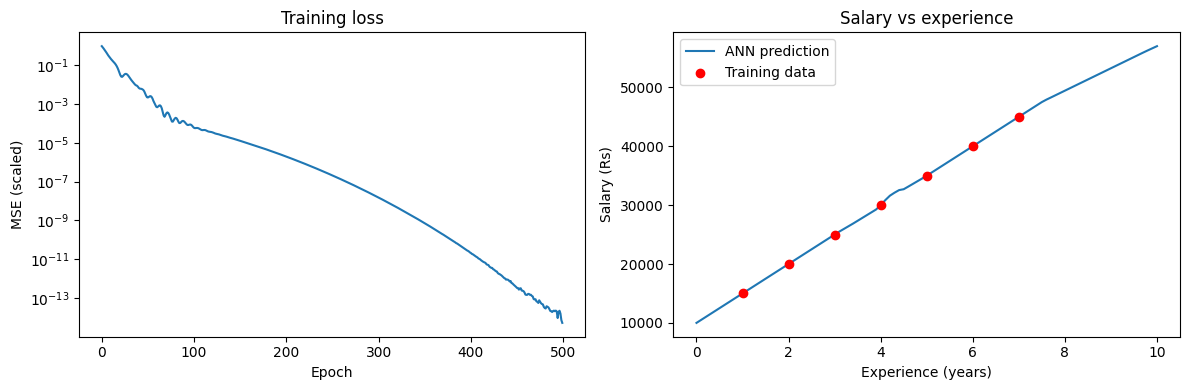

In [7]:
# ===========================================================================
# TASK 3 - Train the model
# ===========================================================================
history = model.fit(x_scaled, y_scaled, epochs=500, verbose=0)
print(f"\nTraining finished. Final loss (MSE, scaled units): {history.history['loss'][-1]:.6f}")


def predict_salary(years):
    """Scale the input, run the network, convert the answer back to rupees."""
    x = (np.array([[years]], dtype=float) - x_mean) / x_std
    return float(model.predict(x, verbose=0)[0, 0] * y_std + y_mean)


print("\nCheck on the training data:")
print(" Years | Actual (Rs) | Predicted (Rs)")
for x, y in zip(experience.ravel(), salary.ravel()):
    print(f" {x:5.0f} | {y:>11,.0f} | {predict_salary(x):>14,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"])
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="MSE (scaled)", yscale="log")
grid = np.linspace(0, 10, 101)
axes[1].plot(grid, [predict_salary(g) for g in grid], label="ANN prediction")
axes[1].scatter(experience, salary, color="red", zorder=3, label="Training data")
axes[1].set(title="Salary vs experience", xlabel="Experience (years)", ylabel="Salary (Rs)")
axes[1].legend()
plt.tight_layout()
plt.show()


In [8]:
# ===========================================================================
# TASKS 4-6 - Ask the user, predict, display
# ===========================================================================
while True:
    text = input("\nEnter years of experience (or 'q' to quit): ").strip()
    if text.lower() in ("q", "quit", "exit", ""):
        print("Goodbye.")
        break
    try:
        years = float(text)
    except ValueError:
        print("Please enter a number, e.g. 3 or 4.5")
        continue
    if years < 0 or years > 50:
        print("Please enter a value between 0 and 50 years.")
        continue

    predicted = predict_salary(years)
    print(f"Predicted salary for {years:g} years of experience: Rs {predicted:,.0f}")
    if years < experience.min() or years > experience.max():
        print(f"  Note: the model was trained on 1-7 years only, so this is an "
              f"extrapolation and may be less reliable.")


Enter years of experience (or 'q' to quit): 10
Predicted salary for 10 years of experience: Rs 56,994
  Note: the model was trained on 1-7 years only, so this is an extrapolation and may be less reliable.

Enter years of experience (or 'q' to quit): 5
Predicted salary for 5 years of experience: Rs 35,000

Enter years of experience (or 'q' to quit): 9
Predicted salary for 9 years of experience: Rs 53,241
  Note: the model was trained on 1-7 years only, so this is an extrapolation and may be less reliable.

Enter years of experience (or 'q' to quit): 7
Predicted salary for 7 years of experience: Rs 45,000

Enter years of experience (or 'q' to quit): q
Goodbye.
